In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
zip_path = "/content/drive/MyDrive/Colab Notebooks/Plant_leaf_diseases_dataset_without_augmentation.zip"
print("File exists:", os.path.exists(zip_path))

File exists: True


In [ ]:
import zipfile
extract_path = "/content/plant_disease_dataset"
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)
print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import os
for root, dirs, files in os.walk(extract_path):
    print("Folder:", root)
    print("Subfolders:", dirs[:10])
    print("Number of files:", len(files))
    if root.count(os.sep) >= extract_path.count(os.sep) + 2:
        dirs[:] = []

Folder: /content/plant_disease_dataset
Subfolders: ['Plant_leave_diseases_dataset_without_augmentation']
Number of files: 0
Folder: /content/plant_disease_dataset/Plant_leave_diseases_dataset_without_augmentation
Subfolders: ['Apple___healthy', 'Corn___Northern_Leaf_Blight', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Late_blight', 'Corn___healthy', 'Tomato___Leaf_Mold', 'Apple___Cedar_apple_rust', 'Orange___Haunglongbing_(Citrus_greening)', 'Potato___Late_blight', 'Background_without_leaves']
Number of files: 0
Folder: /content/plant_disease_dataset/Plant_leave_diseases_dataset_without_augmentation/Apple___healthy
Subfolders: []
Number of files: 1645
Folder: /content/plant_disease_dataset/Plant_leave_diseases_dataset_without_augmentation/Corn___Northern_Leaf_Blight
Subfolders: []
Number of files: 985
Folder: /content/plant_disease_dataset/Plant_leave_diseases_dataset_without_augmentation/Tomato___Tomato_Yellow_Leaf_Curl_Virus
Subfolders: []
Number of files: 5357
Folder: /conte

Import the required libraries

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing import image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

###EDA Process

Check class distribution

In [ ]:
import os
import pandas as pd

data_dir = "/content/plant_disease_dataset/Plant_leave_diseases_dataset_without_augmentation"

class_names = sorted([
    folder for folder in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, folder))
])

print("Dataset path exists:", os.path.exists(data_dir))
print("Total classes:", len(class_names))

Dataset path exists: True
Total classes: 39


In [ ]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

class_counts = {}

for class_name in class_names:
    class_path = os.path.join(data_dir, class_name)

    count = sum(
        1 for file in os.listdir(class_path)
        if file.lower().endswith(image_extensions)
    )

    class_counts[class_name] = count

class_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Image_Count"]
)

print("Total Classes:", len(class_df))
print("Total Images:", class_df["Image_Count"].sum())

display(class_df)

Total Classes: 39
Total Images: 55448


,Class,Image_Count
0,Apple___Apple_scab,630
1,Apple___Black_rot,621
2,Apple___Cedar_apple_rust,275
3,Apple___healthy,1645
4,Background_without_leaves,1143
5,Blueberry___healthy,1502
6,Cherry___Powdery_mildew,1052
7,Cherry___healthy,854
8,Corn___Cercospora_leaf_spot Gray_leaf_spot,513
9,Corn___Common_rust,1192


Visualize the class distribution

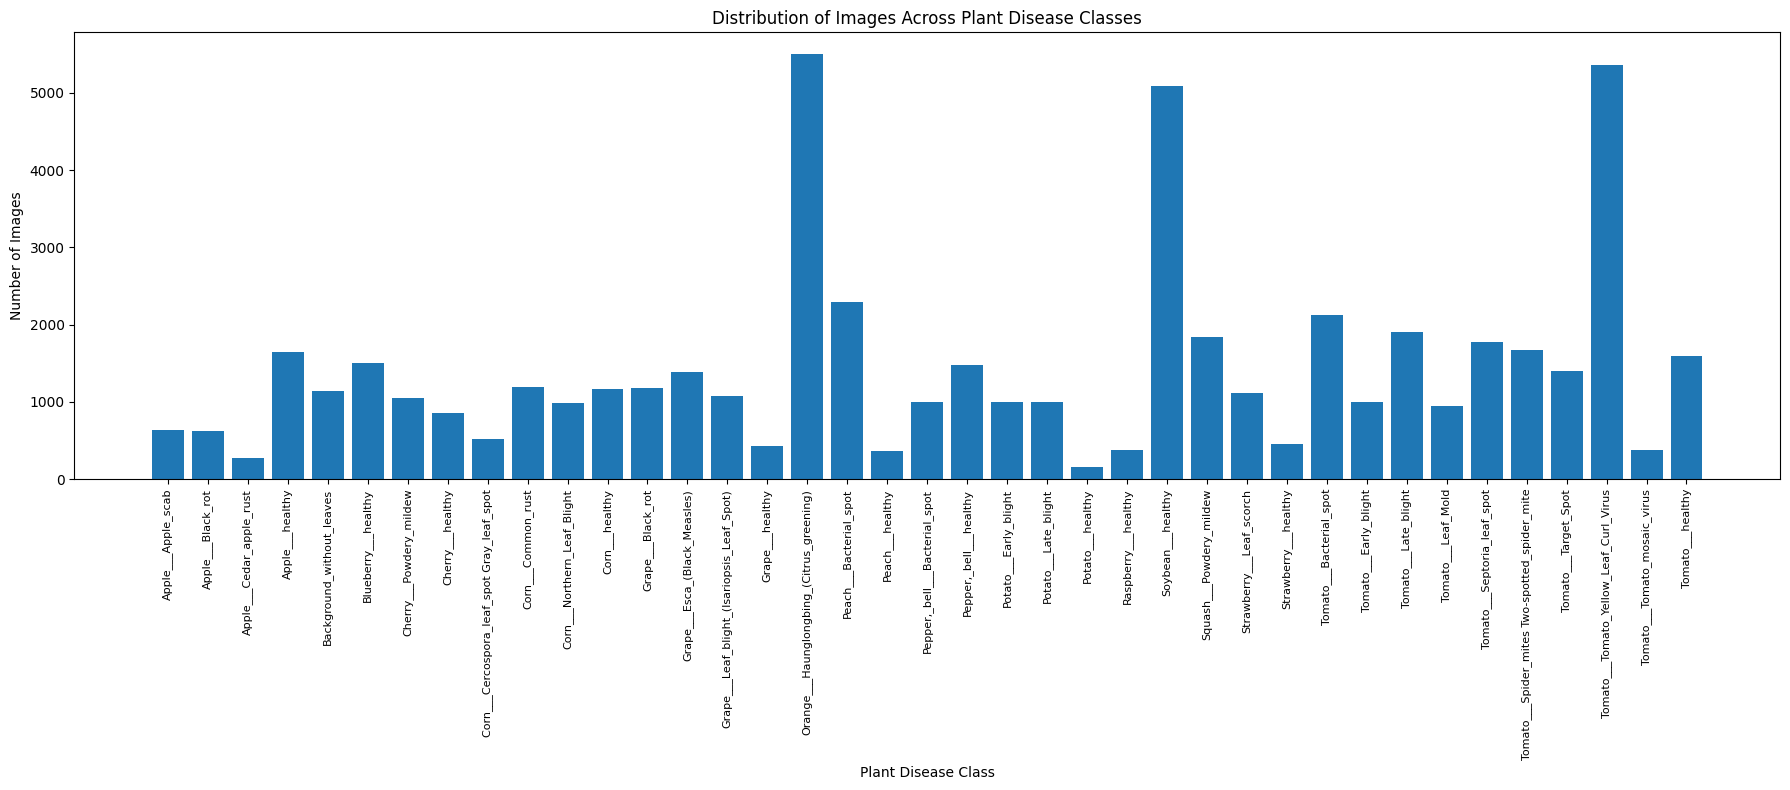

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 8))

plt.bar(class_df["Class"], class_df["Image_Count"])

plt.title("Distribution of Images Across Plant Disease Classes")
plt.xlabel("Plant Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=90, fontsize=8)

plt.tight_layout()
plt.show()

Display sample images

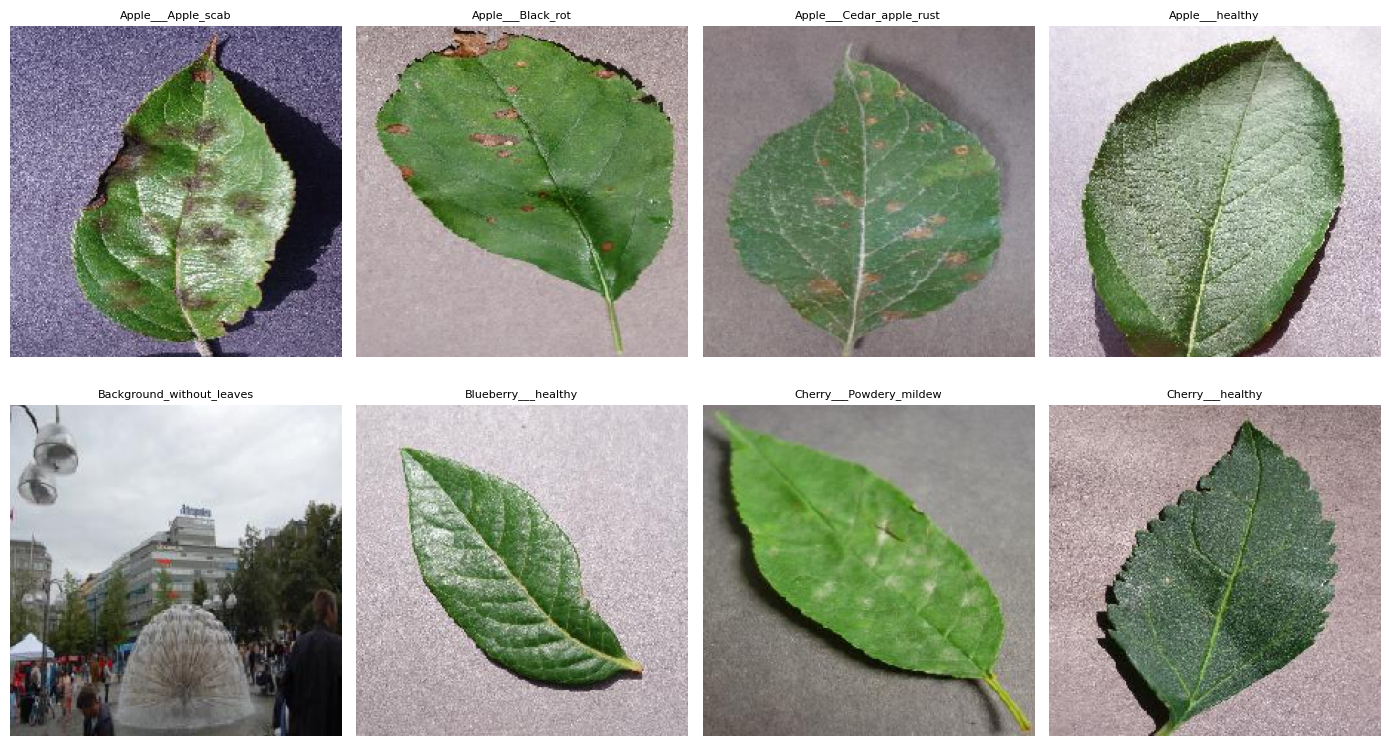

In [ ]:
from tensorflow.keras.preprocessing import image
import os
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))

for i, class_name in enumerate(class_names[:8]):
    class_path = os.path.join(data_dir, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    if image_files:
        img_path = os.path.join(class_path, image_files[0])
        img = image.load_img(img_path, target_size=(224, 224))

        plt.subplot(2, 4, i + 1)
        plt.imshow(img)
        plt.title(class_name, fontsize=8)
        plt.axis("off")

plt.tight_layout()
plt.show()

Data cleaning

In [ ]:
import os
import shutil
import hashlib
from PIL import Image

# Original dataset
data_dir = "/content/plant_disease_dataset/Plant_leave_diseases_dataset_without_augmentation"

# New folder for cleaned data
clean_dir = "/content/plant_disease_cleaned"

os.makedirs(clean_dir, exist_ok=True)

valid_extensions = (".jpg", ".jpeg", ".png", ".bmp")

total_files = 0
valid_files = 0
corrupted_files = 0
unsupported_files = 0
duplicate_files = 0

class_counts_cleaned = {}

for class_name in sorted(os.listdir(data_dir)):

    class_path = os.path.join(data_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    clean_class_path = os.path.join(clean_dir, class_name)
    os.makedirs(clean_class_path, exist_ok=True)

    seen_hashes = set()
    class_valid = 0

    for filename in os.listdir(class_path):

        source_path = os.path.join(class_path, filename)
        total_files += 1

        # Skip unsupported files
        if not filename.lower().endswith(valid_extensions):
            unsupported_files += 1
            continue

        # Skip empty files
        if os.path.getsize(source_path) == 0:
            corrupted_files += 1
            continue

        # Verify image integrity
        try:
            with Image.open(source_path) as img:
                img.verify()

            # Hash exact file contents to detect exact duplicates
            with open(source_path, "rb") as f:
                file_hash = hashlib.sha256(f.read()).hexdigest()

            if file_hash in seen_hashes:
                duplicate_files += 1
                continue

            seen_hashes.add(file_hash)

            shutil.copy2(
                source_path,
                os.path.join(clean_class_path, filename)
            )

            valid_files += 1
            class_valid += 1

        except Exception:
            corrupted_files += 1

    class_counts_cleaned[class_name] = class_valid

print("DATA CLEANING COMPLETED")
print("-----------------------")
print("Total files scanned:", total_files)
print("Valid images copied:", valid_files)
print("Corrupted/empty files:", corrupted_files)
print("Unsupported files:", unsupported_files)
print("Exact duplicate files removed:", duplicate_files)
print("Cleaned dataset path:", clean_dir)
print("Total classes:", len(class_counts_cleaned))

print("\nImages remaining per class:")
for class_name, count in class_counts_cleaned.items():
    print(class_name, ":", count)

DATA CLEANING COMPLETED
-----------------------
Total files scanned: 55448
Valid images copied: 55425
Corrupted/empty files: 0
Unsupported files: 0
Exact duplicate files removed: 23
Cleaned dataset path: /content/plant_disease_cleaned
Total classes: 39

Images remaining per class:
Apple___Apple_scab : 630
Apple___Black_rot : 621
Apple___Cedar_apple_rust : 275
Apple___healthy : 1638
Background_without_leaves : 1141
Blueberry___healthy : 1502
Cherry___Powdery_mildew : 1052
Cherry___healthy : 854
Corn___Cercospora_leaf_spot Gray_leaf_spot : 513
Corn___Common_rust : 1192
Corn___Northern_Leaf_Blight : 985
Corn___healthy : 1162
Grape___Black_rot : 1180
Grape___Esca_(Black_Measles) : 1383
Grape___Leaf_blight_(Isariopsis_Leaf_Spot) : 1076
Grape___healthy : 423
Orange___Haunglongbing_(Citrus_greening) : 5507
Peach___Bacterial_spot : 2297
Peach___healthy : 360
Pepper,_bell___Bacterial_spot : 997
Pepper,_bell___healthy : 1478
Potato___Early_blight : 1000
Potato___Late_blight : 1000
Potato___healt

In [ ]:
import os
from collections import defaultdict

data_dir = "/content/plant_disease_dataset/Plant_leave_diseases_dataset_without_augmentation"

plant_types = defaultdict(lambda: {"healthy": [], "disease": []})

for class_name in os.listdir(data_dir):
    class_path = os.path.join(data_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    if class_name == "Background_without_leaves":
        continue

    # Extract plant name from the class folder
    plant_name = class_name.split("___")[0]

    if "healthy" in class_name.lower():
        plant_types[plant_name]["healthy"].append(class_name)
    else:
        plant_types[plant_name]["disease"].append(class_name)

print("PLANT TYPES WITH BOTH HEALTHY AND DISEASE CLASSES")

for plant, categories in sorted(plant_types.items()):
    if categories["healthy"] and categories["disease"]:
        print(plant)

print("\nPLANT TYPES TO REMOVE")

for plant, categories in sorted(plant_types.items()):
    if not (categories["healthy"] and categories["disease"]):
        print(
            plant,
            "| Healthy:", categories["healthy"],
            "| Disease:", categories["disease"]
        )

PLANT TYPES WITH BOTH HEALTHY AND DISEASE CLASSES
Apple
Cherry
Corn
Grape
Peach
Pepper,_bell
Potato
Strawberry
Tomato

PLANT TYPES TO REMOVE
Blueberry | Healthy: ['Blueberry___healthy'] | Disease: []
Orange | Healthy: [] | Disease: ['Orange___Haunglongbing_(Citrus_greening)']
Raspberry | Healthy: ['Raspberry___healthy'] | Disease: []
Soybean | Healthy: ['Soybean___healthy'] | Disease: []
Squash | Healthy: [] | Disease: ['Squash___Powdery_mildew']


Clean the dataset based on plant types

In [ ]:
import os
import shutil

# Original dataset
data_dir = "/content/plant_disease_dataset/Plant_leave_diseases_dataset_without_augmentation"

# New cleaned dataset
clean_dir = "/content/plant_disease_cleaned"

# Plant types that have both healthy and disease classes
keep_plants = [
    "Apple",
    "Cherry",
    "Corn",
    "Grape",
    "Peach",
    "Pepper,_bell",
    "Potato",
    "Strawberry",
    "Tomato"
]

# Recreate output folder to avoid leftover classes from previous runs
if os.path.exists(clean_dir):
    shutil.rmtree(clean_dir)

os.makedirs(clean_dir)

for class_name in sorted(os.listdir(data_dir)):

    source_path = os.path.join(data_dir, class_name)

    if not os.path.isdir(source_path):
        continue

    # Exclude background and classes belonging to unwanted plants
    if class_name == "Background_without_leaves":
        continue

    plant_name = class_name.split("___")[0]

    if plant_name not in keep_plants:
        continue

    destination_path = os.path.join(clean_dir, class_name)

    shutil.copytree(source_path, destination_path)

print("Dataset cleaning completed!")
print("Cleaned dataset path:", clean_dir)

# Verify remaining classes and images
remaining_classes = []
total_images = 0

for class_name in sorted(os.listdir(clean_dir)):
    class_path = os.path.join(clean_dir, class_name)

    if os.path.isdir(class_path):
        image_count = sum(
            1 for f in os.listdir(class_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        )

        remaining_classes.append(class_name)
        total_images += image_count

        print(f"{class_name}: {image_count} images")

print("\nTotal remaining classes:", len(remaining_classes))
print("Total remaining images:", total_images)

Dataset cleaning completed!
Cleaned dataset path: /content/plant_disease_cleaned
Apple___Apple_scab: 630 images
Apple___Black_rot: 621 images
Apple___Cedar_apple_rust: 275 images
Apple___healthy: 1645 images
Cherry___Powdery_mildew: 1052 images
Cherry___healthy: 854 images
Corn___Cercospora_leaf_spot Gray_leaf_spot: 513 images
Corn___Common_rust: 1192 images
Corn___Northern_Leaf_Blight: 985 images
Corn___healthy: 1162 images
Grape___Black_rot: 1180 images
Grape___Esca_(Black_Measles): 1383 images
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076 images
Grape___healthy: 423 images
Peach___Bacterial_spot: 2297 images
Peach___healthy: 360 images
Pepper,_bell___Bacterial_spot: 997 images
Pepper,_bell___healthy: 1478 images
Potato___Early_blight: 1000 images
Potato___Late_blight: 1000 images
Potato___healthy: 152 images
Strawberry___Leaf_scorch: 1109 images
Strawberry___healthy: 456 images
Tomato___Bacterial_spot: 2127 images
Tomato___Early_blight: 1000 images
Tomato___Late_blight: 1909 imag

Split the cleaned dataset

In [ ]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

clean_dir = "/content/plant_disease_cleaned"

# Collect image paths and their labels
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

image_paths = []
labels = []

for class_name in sorted(os.listdir(clean_dir)):
    class_path = os.path.join(clean_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):
        if filename.lower().endswith(image_extensions):
            image_paths.append(os.path.join(class_path, filename))
            labels.append(class_name)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

print("Total images:", len(df))
print("Total classes:", df["label"].nunique())

# Split 80% training and 20% temporary data
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

# Split temporary data equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("\nTraining images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTraining classes:", train_df["label"].nunique())
print("Validation classes:", val_df["label"].nunique())
print("Testing classes:", test_df["label"].nunique())

Total images: 40000
Total classes: 33

Training images: 32000
Validation images: 4000
Testing images: 4000

Training classes: 33
Validation classes: 33
Testing classes: 33


In [ ]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = len(class_names)

print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Image size: 224 x 224
Batch size: 32
Number of classes: 39


Create image preprocessing function

In [ ]:
def load_and_preprocess_image(image_path, label):
    # Read image
    image = tf.io.read_file(image_path)

    # Decode image
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Set image shape
    image.set_shape([None, None, 3])

    # Resize image
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])

    # Apply MobileNetV2 preprocessing
    image = preprocess_input(image)

    return image, label

Convert labels into numbers

In [ ]:
class_names = sorted(train_df["label"].unique())

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["label_id"] = train_df["label"].map(class_to_index)
val_df["label_id"] = val_df["label"].map(class_to_index)
test_df["label_id"] = test_df["label"].map(class_to_index)

print("Number of classes:", len(class_names))
print("Sample class mapping:")

for name in class_names[:5]:
    print(name, "=", class_to_index[name])

Number of classes: 33
Sample class mapping:
Apple___Apple_scab = 0
Apple___Black_rot = 1
Apple___Cedar_apple_rust = 2
Apple___healthy = 3
Cherry___Powdery_mildew = 4


Create TensorFlow datasets

In [ ]:
def create_dataset(dataframe, training=False):
    image_paths = dataframe["image_path"].values
    labels = dataframe["label_id"].values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=10000,
            seed=42
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Datasets created successfully!")

Datasets created successfully!


Verify image size and labels

In [ ]:
for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Pixel value range:",
          tf.reduce_min(images).numpy(),
          "to",
          tf.reduce_max(images).numpy())

Images shape: (32, 224, 224, 3)
Labels shape: (32,)
Pixel value range: -1.0 to 1.0


Create the MobileNetV2 model

Load the pretrained model

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dropout,
    Dense
)
from tensorflow.keras.models import Model

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers initially
base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Total base model layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 loaded successfully!
Total base model layers: 154


Add our classification layers

In [ ]:
inputs = Input(shape=(224, 224, 3))

# Extract image features
x = base_model(inputs, training=False)

# Convert feature maps into a vector
x = GlobalAveragePooling2D()(x)

# Reduce overfitting
x = Dropout(0.3)(x)

# Predict one of 33 classes
outputs = Dense(NUM_CLASSES, activation="softmax")(x)

model = Model(inputs, outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 39)             │        49,959 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,307,943 (8.80 MB)

 Trainable params: 49,959 (195.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
print("Training classes:", train_df["label"].nunique())
print("Validation classes:", val_df["label"].nunique())
print("Testing classes:", test_df["label"].nunique())
print("NUM_CLASSES:", NUM_CLASSES)
print("Class names count:", len(class_names))

Training classes: 33
Validation classes: 33
Testing classes: 33
NUM_CLASSES: 39
Class names count: 33


In [ ]:
NUM_CLASSES = len(class_names)

print("Updated NUM_CLASSES:", NUM_CLASSES)

Updated NUM_CLASSES: 33


In [ ]:
Recreate The Model

In [ ]:
inputs = tf.keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Output shape:", model.output_shape)

Output shape: (None, 33)


Train the model

In [ ]:
# Train the model for 20 epochs
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Epoch 1/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 40s 40ms/step - accuracy: 0.9450 - loss: 0.1647 - val_accuracy: 0.9467 - val_loss: 0.1650
Epoch 2/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 40s 40ms/step - accuracy: 0.9470 - loss: 0.1530 - val_accuracy: 0.9482 - val_loss: 0.1607
Epoch 3/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 40s 38ms/step - accuracy: 0.9488 - loss: 0.1482 - val_accuracy: 0.9507 - val_loss: 0.1517
Epoch 4/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 42s 42ms/step - accuracy: 0.9499 - loss: 0.1450 - val_accuracy: 0.9492 - val_loss: 0.1537
Epoch 5/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 42s 42ms/step - accuracy: 0.9522 - loss: 0.1363 - val_accuracy: 0.9498 - val_loss: 0.1553
Epoch 6/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 42s 42ms/step - accuracy: 0.9502 - loss: 0.1430 - val_accuracy: 0.9513 - val_loss: 0.1580
Epoch 7/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 41s 40ms/step - accuracy: 0.9518 - loss: 0.1359 - val_accuracy: 0.9520 - val_loss: 0.1564
Epoch 8/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 45s 45ms/step - accuracy: 0.9557 -

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Stop training if validation loss does not improve
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Save the best model
checkpoint = ModelCheckpoint(
    "best_plant_disease_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/10
 999/1000 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.7051 - loss: 1.0806
Epoch 1: val_loss improved from None to 0.25881, saving model to best_plant_disease_model.keras

Epoch 1: finished saving model to best_plant_disease_model.keras
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 69s 56ms/step - accuracy: 0.8272 - loss: 0.6038 - val_accuracy: 0.9323 - val_loss: 0.2588
Epoch 2/10
 999/1000 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9135 - loss: 0.2752
Epoch 2: val_loss improved from 0.25881 to 0.20604, saving model to best_plant_disease_model.keras

Epoch 2: finished saving model to best_plant_disease_model.keras
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 62s 45ms/step - accuracy: 0.9157 - loss: 0.2653 - val_accuracy: 0.9390 - val_loss: 0.2060
Epoch 3/10
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9267 - loss: 0.2236
Epoch 3: val_loss improved from 0.20604 to 0.19513, saving model to best_plant_disease_model.keras

Epoch 3: finished saving model to best_plant_disease_model.keras

In [ ]:
print("Current learning rate:",
      float(model.optimizer.learning_rate.numpy()))

Current learning rate: 0.0010000000474974513


In [ ]:
LEARNING_RATE = 0.0001
EPOCHS = 20

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print(
    "Current learning rate:",
    float(model.optimizer.learning_rate.numpy())
)

Current learning rate: 9.999999747378752e-05


In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Epoch 1/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 52s 45ms/step - accuracy: 0.9651 - loss: 0.1032 - val_accuracy: 0.9572 - val_loss: 0.1442
Epoch 2/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 78s 44ms/step - accuracy: 0.9646 - loss: 0.0991 - val_accuracy: 0.9585 - val_loss: 0.1420
Epoch 3/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 43s 42ms/step - accuracy: 0.9662 - loss: 0.0963 - val_accuracy: 0.9588 - val_loss: 0.1420
Epoch 4/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 43s 43ms/step - accuracy: 0.9650 - loss: 0.0998 - val_accuracy: 0.9570 - val_loss: 0.1417
Epoch 5/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 41s 41ms/step - accuracy: 0.9667 - loss: 0.0943 - val_accuracy: 0.9590 - val_loss: 0.1427
Epoch 6/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 42s 42ms/step - accuracy: 0.9668 - loss: 0.0956 - val_accuracy: 0.9605 - val_loss: 0.1430
Epoch 7/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 46s 46ms/step - accuracy: 0.9672 - loss: 0.0943 - val_accuracy: 0.9585 - val_loss: 0.1443
Epoch 8/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 78s 42ms/step - accuracy: 0.9676 -

Test the model

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.9560 - loss: 0.1266
Test Loss: 0.12659485638141632
Test Accuracy: 0.9559999704360962
Test Accuracy (%): 95.59999704360962


Confusion matrix, precision, recall and F1-score

125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step
Test Accuracy: 0.956

Classification Report:

                                               precision    recall  f1-score   support

                           Apple___Apple_scab       0.94      0.98      0.96        63
                            Apple___Black_rot       0.98      1.00      0.99        62
                     Apple___Cedar_apple_rust       1.00      0.93      0.96        27
                              Apple___healthy       0.99      0.99      0.99       165
                      Cherry___Powdery_mildew       1.00      1.00      1.00       105
                             Cherry___healthy       1.00      1.00      1.00        85
   Corn___Cercospora_leaf_spot Gray_leaf_spot       0.82      0.79      0.80        52
                           Corn___Common_rust       0.99      1.00      1.00       119
                  Corn___Northern_Leaf_Blight       0.89      0.91      0.90        99
                               Corn___hea

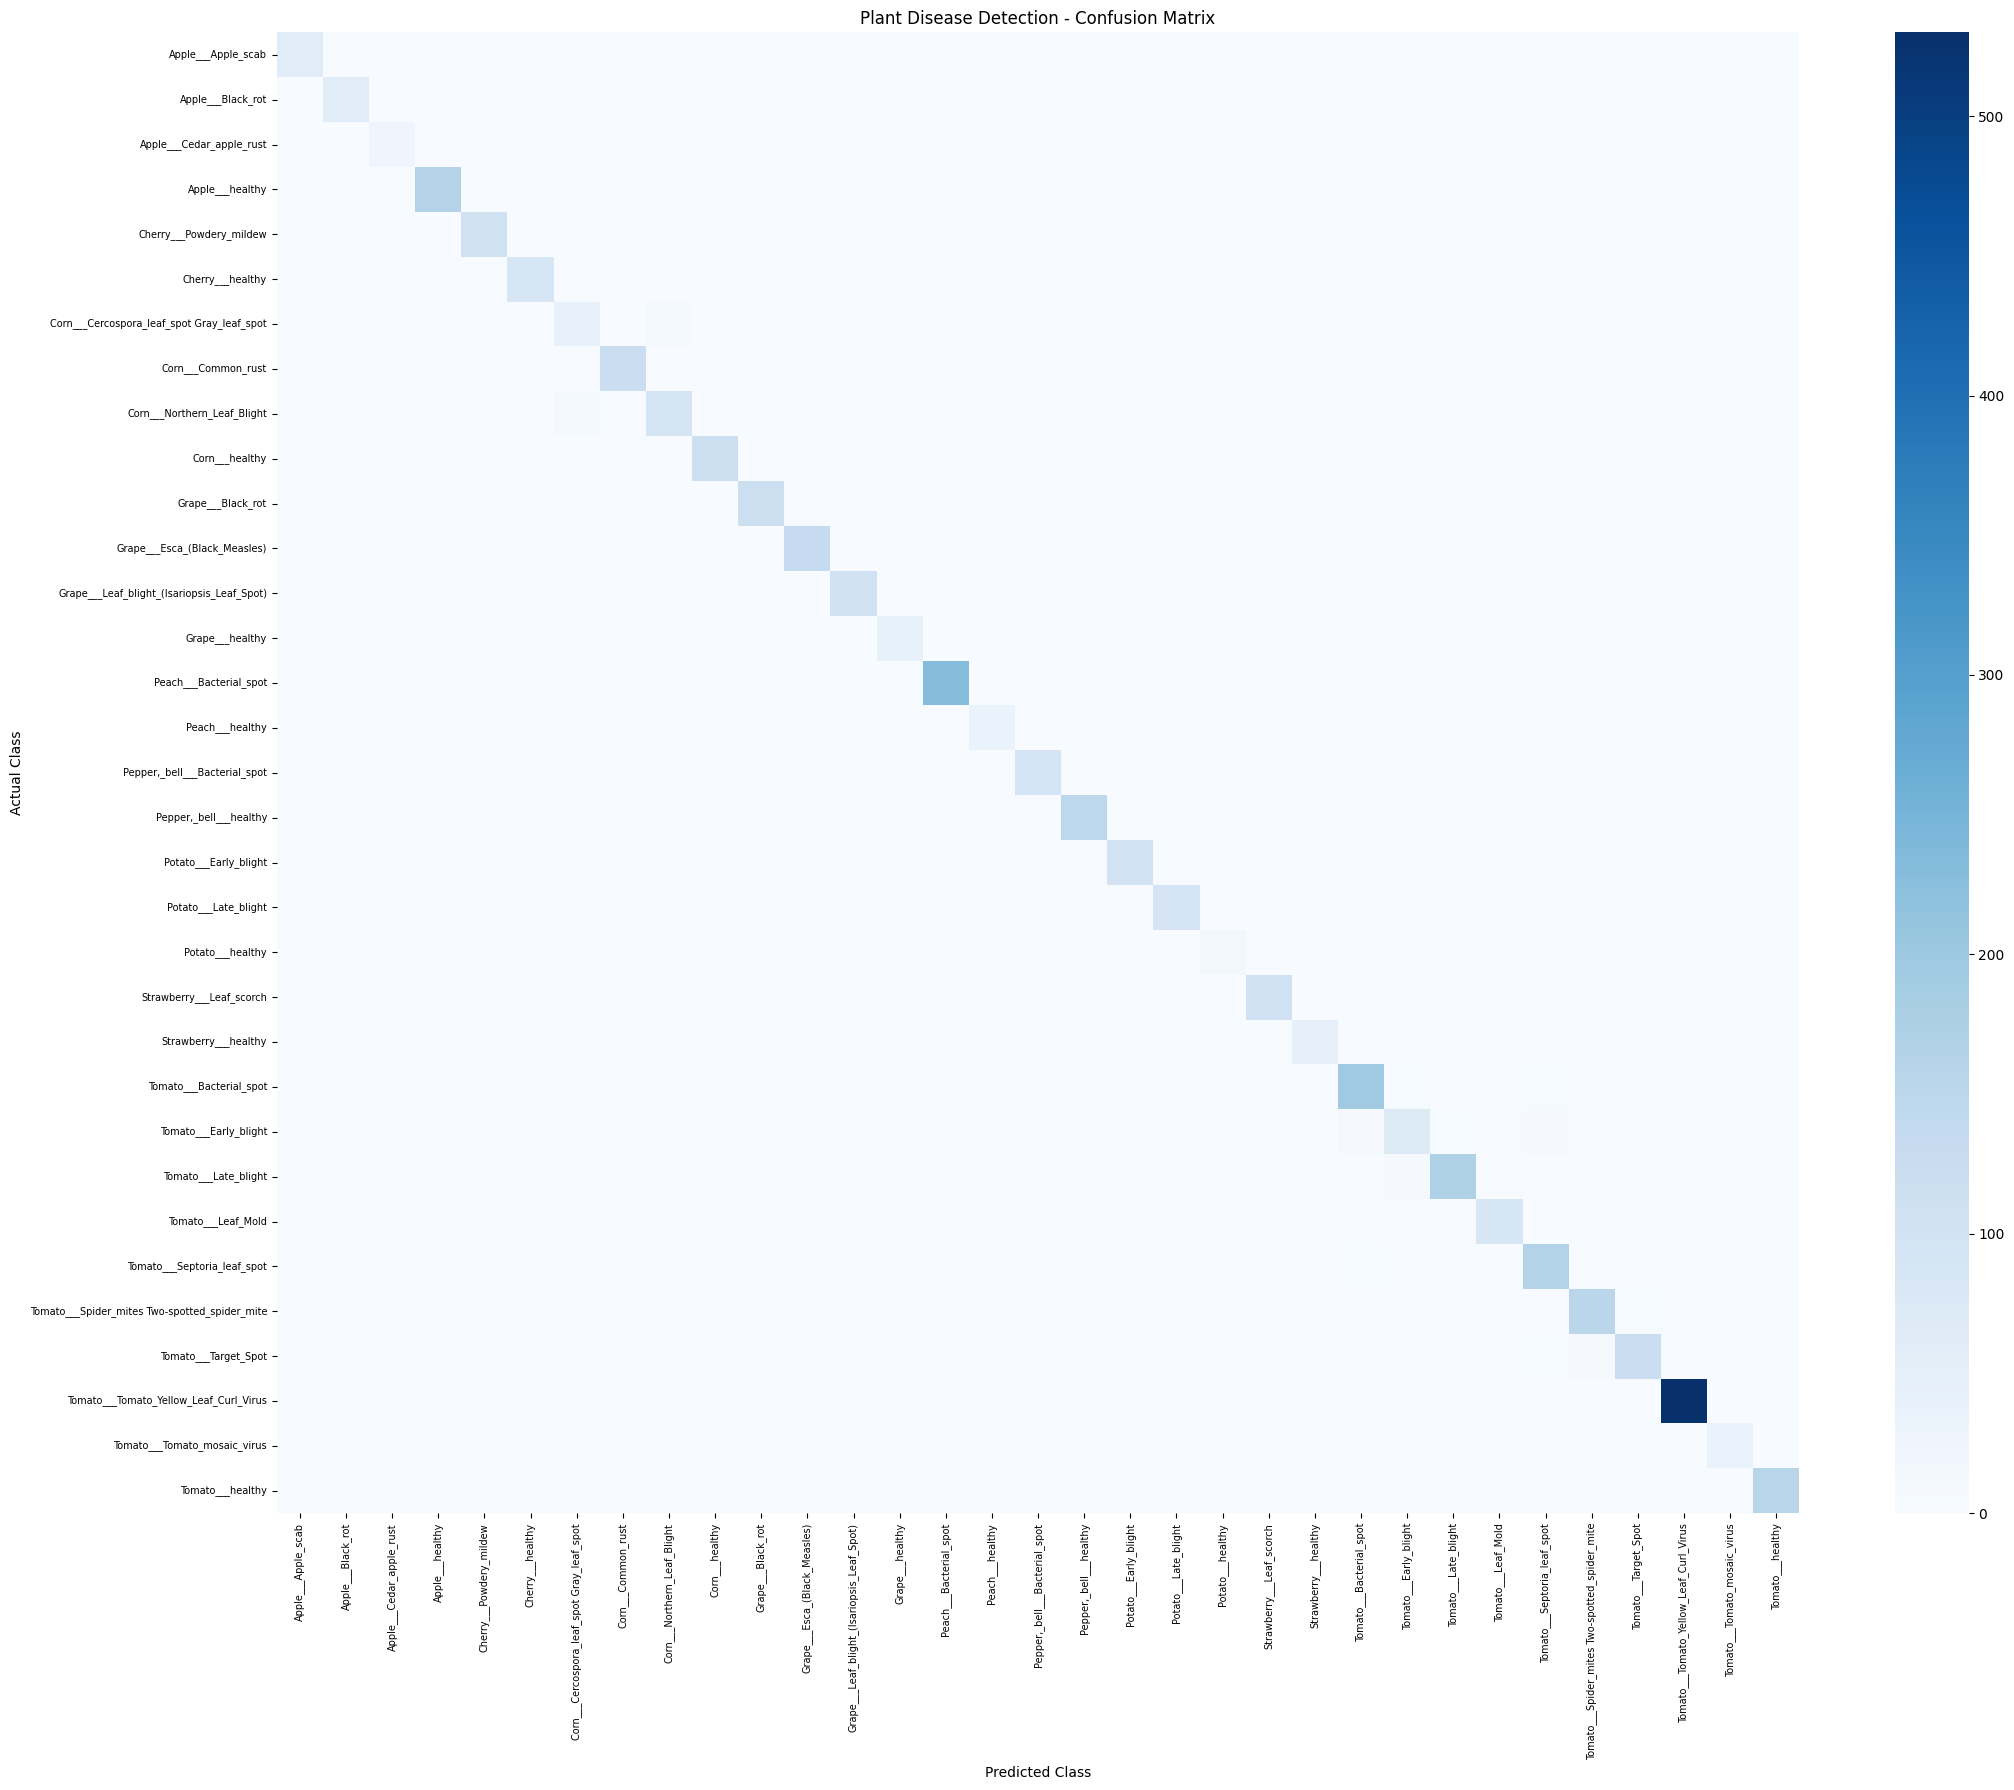

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Get true labels from test dataset
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predict probabilities
y_prob = model.predict(test_ds)

# Convert probabilities to predicted class IDs
y_pred = np.argmax(y_prob, axis=1)

# Calculate accuracy
print("Test Accuracy:", accuracy_score(y_true, y_pred))

# Classification report
print("\nClassification Report:\n")
print(
    classification_report(
        y_true,
        y_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

plt.figure(figsize=(22, 18))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Plant Disease Detection - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.show()

In [ ]:
model.save("plant_disease_mobilenetv2.keras")

print("Model saved successfully!")

Model saved successfully!
